# Last visitation: the area looked at last before confirming

Which area do people look at last before they confirm their answer, and does it depend on the answer they chose? Each trial records `last_lbl_before_confirm`: the area (the question or one of the four answers) of the last fixation that started at or before the confirming button press. The data are Study 1 (360 participants, 19,436 trials), read from the word-level table and reduced to one row per trial before counting. The figure has one panel per chosen answer (A to D, where A is always the correct answer) and one bar per area: the share, or the number, of those trials that ended on that area. Trials with no last look are left out. Most choices are A, so the panels for B, C and D rest on far fewer trials. The figure itself does not say which group it shows (the group goes only into the saved file name), so each figure below is named in the text above it.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import matplotlib.pyplot as plt
from src.config import columns as C
from src.config.datasets import dataset
from src.features.build import load_model_input
from src.features.scope import split_participant_groups
from src.analyses.last_visitation.plots import plot_last_label_before_confirm_freq

# One row per word; each trial's values repeat on every word.
all_participants = load_model_input(dataset("l1"))

  grains: interest_areas (760628, 23), areas_answers (97180, 19), trials (19436, 89)


## 1. The input

What the figure counts, at one row per trial: who, which trial, the answer chosen, and the area looked at last before confirming.

In [2]:
trials = all_participants[
    [C.PARTICIPANT_ID, C.TRIAL_ID, C.SELECTED_ANSWER_LABEL_COLUMN, C.LAST_LBL_BEFORE_CONFIRM]
].drop_duplicates([C.PARTICIPANT_ID, C.TRIAL_ID])
print(f"{len(trials):,} trials, {trials[C.LAST_LBL_BEFORE_CONFIRM].isna().sum()} with no last look")
trials.head()

19,436 trials, 0 with no last look


,participant_id,TRIAL_INDEX,selected_answer_label,last_lbl_before_confirm
0,l42_2070,4,A,answer_A
33,l42_2070,5,A,answer_C
73,l42_2070,6,A,answer_C
114,l42_2070,7,A,answer_A
149,l42_2070,8,A,answer_C


## 2. All participants, as shares

Each panel is one chosen answer, and its bars add up to 1. The table holds the same numbers: one row per chosen answer, one column per area looked at last. In every panel the tallest bar is the chosen answer.

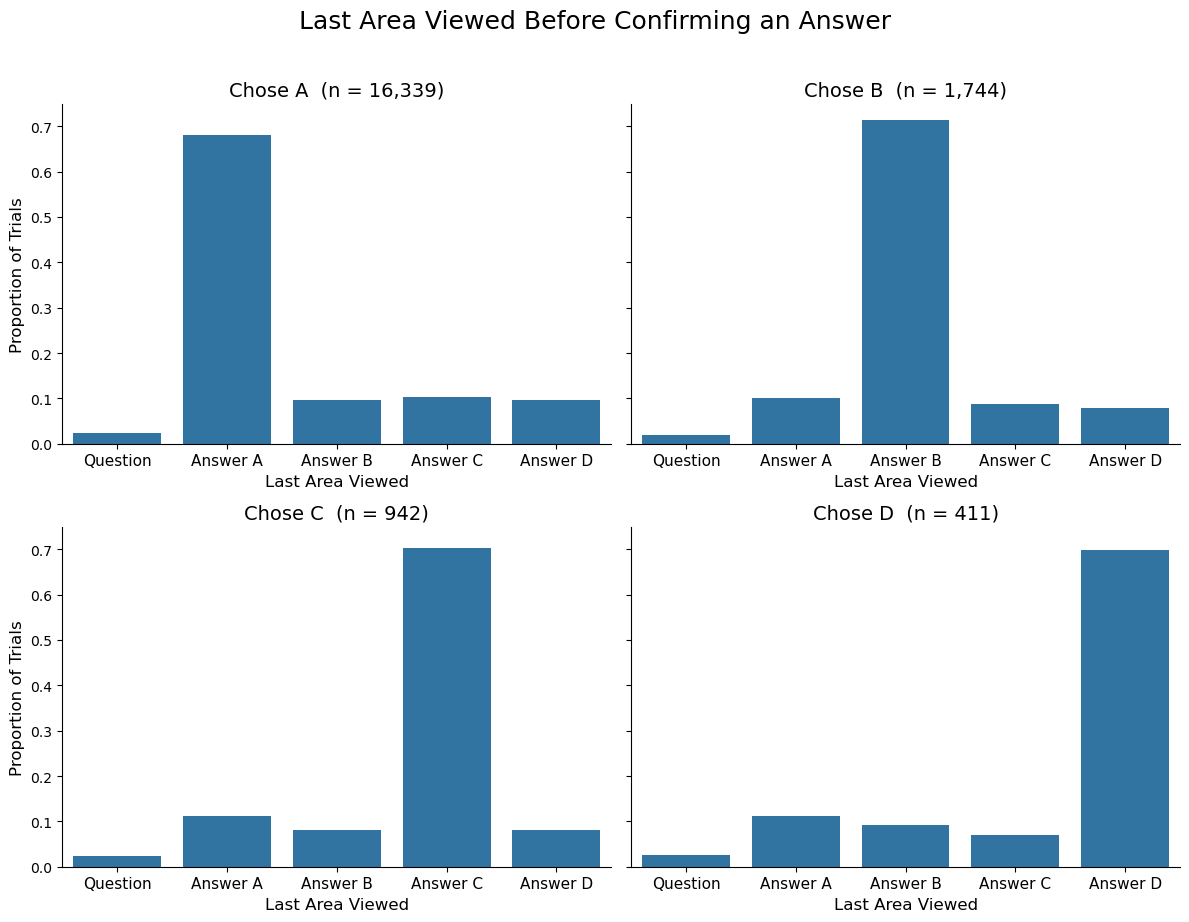

last_lbl_before_confirm,answer_A,answer_B,answer_C,answer_D,question
selected_answer,,,,,
A,0.682,0.095,0.103,0.096,0.024
B,0.100,0.713,0.088,0.080,0.019
C,0.111,0.082,0.702,0.081,0.024
D,0.112,0.092,0.071,0.698,0.027


In [3]:
fig, summary = plot_last_label_before_confirm_freq(
    all_participants, normalize=True, h_or_g="all_participants", save=False
)
plt.show()
summary.pivot(index="selected_answer", columns=C.LAST_LBL_BEFORE_CONFIRM, values="proportion").round(3)

## 3. The same, as numbers of trials

`normalize=False` plots counts instead of shares. The panels share one y-axis, which shows how unevenly the trials are spread across the four chosen answers.

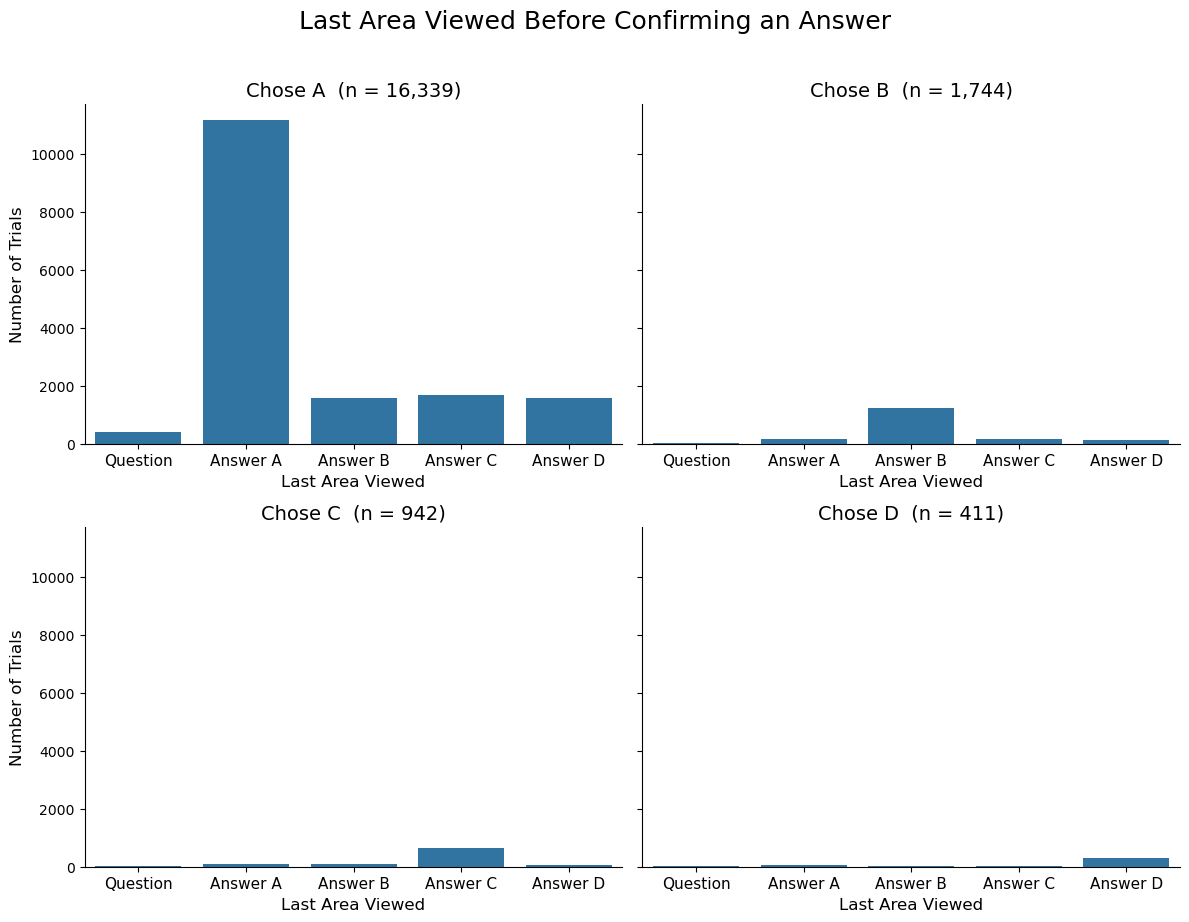

last_lbl_before_confirm,answer_A,answer_B,answer_C,answer_D,question
selected_answer,,,,,
A,11140,1559,1684,1563,393
B,175,1243,154,139,33
C,105,77,661,76,23
D,46,38,29,287,11


In [4]:
fig, counts = plot_last_label_before_confirm_freq(
    all_participants, normalize=False, h_or_g="all_participants", save=False
)
plt.show()
counts.pivot(index="selected_answer", columns=C.LAST_LBL_BEFORE_CONFIRM, values="n")

## 4. Hunters and gatherers

The same figure for each group separately, as shares. Hunters saw the question before reading the text; gatherers read the text first.

**Hunters:**

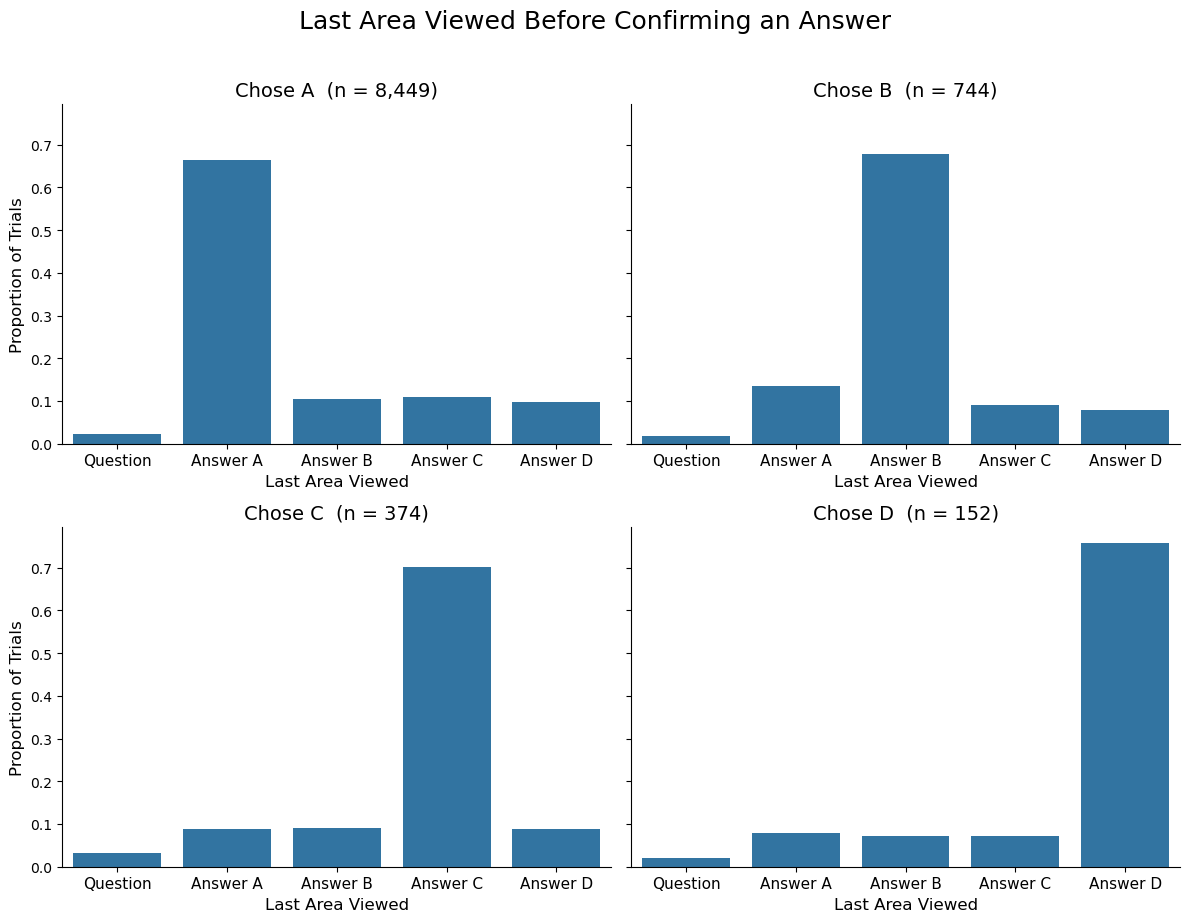

last_lbl_before_confirm,answer_A,answer_B,answer_C,answer_D,question
selected_answer,,,,,
A,0.665,0.104,0.110,0.099,0.023
B,0.134,0.679,0.091,0.078,0.017
C,0.088,0.091,0.701,0.088,0.032
D,0.079,0.072,0.072,0.757,0.020


In [5]:
groups = split_participant_groups(all_participants, include_all=False)
fig, hunters = plot_last_label_before_confirm_freq(
    groups["hunters"], normalize=True, h_or_g="hunters", save=False
)
plt.show()
hunters.pivot(index="selected_answer", columns=C.LAST_LBL_BEFORE_CONFIRM, values="proportion").round(3)

**Gatherers:**

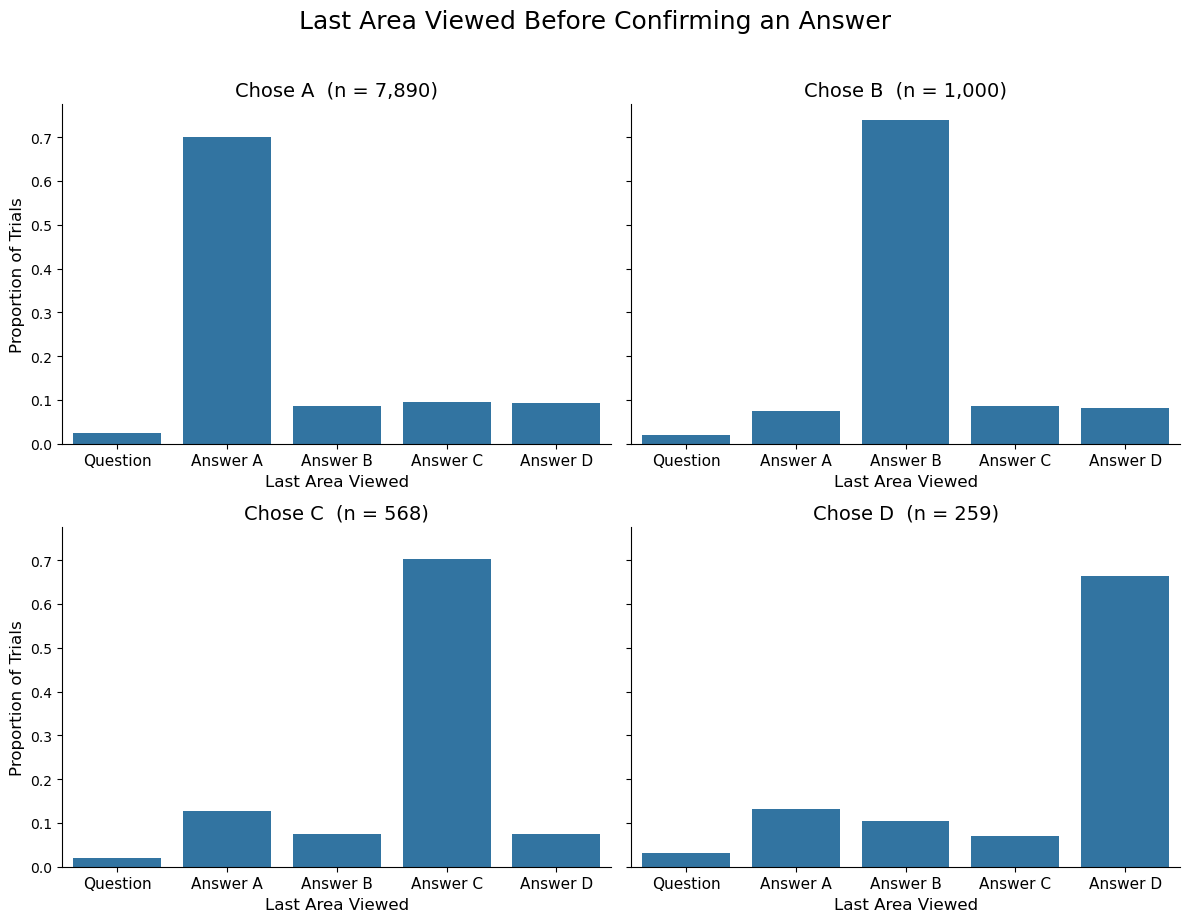

last_lbl_before_confirm,answer_A,answer_B,answer_C,answer_D,question
selected_answer,,,,,
A,0.700,0.087,0.096,0.092,0.025
B,0.075,0.738,0.086,0.081,0.020
C,0.127,0.076,0.702,0.076,0.019
D,0.131,0.104,0.069,0.664,0.031


In [6]:
fig, gatherers = plot_last_label_before_confirm_freq(
    groups["gatherers"], normalize=True, h_or_g="gatherers", save=False
)
plt.show()
gatherers.pivot(index="selected_answer", columns=C.LAST_LBL_BEFORE_CONFIRM, values="proportion").round(3)

`run_all_last_label_before_confirm_plots` draws this figure for hunters, gatherers and all participants in one call, with the same text options (`title`, `x_label`, `y_label`, `panel_title_fmt`, `show_n`). `python scripts/run_analysis.py --name last_visitation` runs it and saves the figures and tables under `reports/last_visitation/`.